In [1]:
# ==============================================================================
# ASSIGNMENT: MULTILINGUAL NAMED ENTITY RECOGNITION (NER) ANALYSIS
# COVERING ENGLISH AND HINDI
# ==============================================================================

# ==============================================================================
# CELL 1: ENVIRONMENT SETUP & DEPENDENCIES
# ==============================================================================
# Installs NLP, scraping, visualization libraries, and a Devanagari font.

!wget -q https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSansDevanagari/NotoSansDevanagari-Regular.ttf -O NotoSansDevanagari.ttf
!pip install -q spacy nltk pandas matplotlib seaborn wordcloud transformers datasets beautifulsoup4 requests torch

import re
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns
from bs4 import BeautifulSoup
from wordcloud import WordCloud
import spacy
from spacy import displacy
import nltk

from transformers import pipeline
from datasets import load_dataset

# Download NLTK and spaCy assets
nltk.download('brown', quiet=True)
from nltk.corpus import brown

!python -m spacy download en_core_web_sm -q
nlp_en = spacy.load("en_core_web_sm")

# Configure Fonts for Matplotlib
hindi_font_path = "NotoSansDevanagari.ttf"
hindi_font = fm.FontProperties(fname=hindi_font_path, size=12)

print("All libraries installed, models loaded, and fonts configured successfully!")

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
fonts-noto-core is already the newest version (20201225-2).
0 upgraded, 0 newly installed, 0 to remove and 11 not upgraded.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 73.2 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
All libraries installed, models loaded, and fonts configured successfully!


 SECTION 1: ENGLISH NAMED ENTITY RECOGNITION (NLTK BROWN) 

--- Selected English Document (First 250 Words) ---
The Fulton County Grand Jury said Friday an investigation of Atlanta's recent primary election produced `` no evidence '' that any irregularities took place . The jury further said in term-end presentments that the City Executive Committee , which had over-all charge of the election , `` deserves the praise and thanks of the City of Atlanta '' for the manner in which the election was conducted . The September-October term jury had been charged by Fulton Superior Court Judge Durwood Pye to investigate reports of possible `` irregularities '' in the hard-fought primary which was won by Mayor-nominate Ivan Allen Jr. . `` Only a relative handful of such reports was received '' , the jury said , `` considering the widespread interest in the election , the number of voters and the size of this city '' . The jury said it did find that many of Georgia's registration and election laws

,Entity,Label,Start,End
0,The Fulton County Grand Jury,ORG,0,28
1,Friday,DATE,34,40
2,Atlanta,GPE,61,68
3,the City Executive Committee,ORG,211,239
4,the City of Atlanta,GPE,323,342
5,September-October,DATE,403,420
6,Fulton Superior Court,ORG,451,472
7,Durwood Pye,PERSON,479,490
8,Ivan Allen Jr.,PERSON,606,620
9,Georgia,GPE,848,855


/tmp/ipykernel_4522/2350400476.py:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


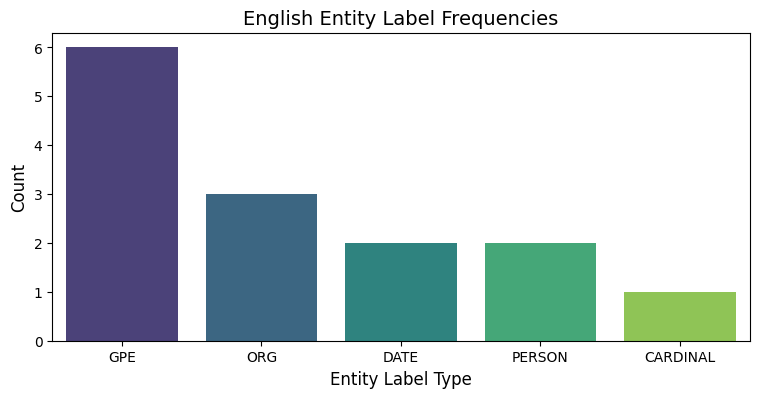

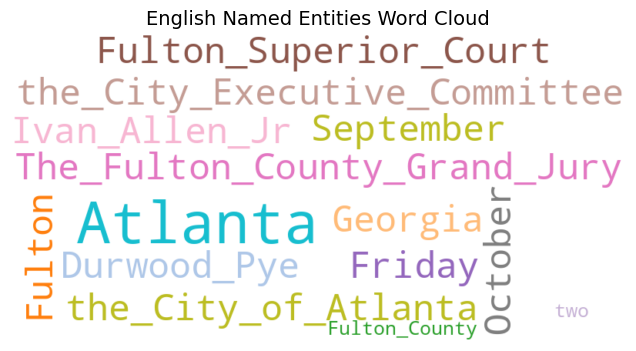

In [2]:
# ==============================================================================
# CELL 2: SECTION 1 - ENGLISH NER PIPELINE (NLTK BROWN CORPUS) [TEACHER CODE]
# ==============================================================================

# entity tables, count plots, word clouds, and displaCy visualizations.

print("="*60)
print(" SECTION 1: ENGLISH NAMED ENTITY RECOGNITION (NLTK BROWN) ")
print("="*60)

# 1. Load English document from Brown corpus
news_file_id = brown.fileids(categories='news')[0]
words_list = brown.words(fileids=news_file_id)[:250]
document_en = " ".join(words_list)

print(f"\n--- Selected English Document (First 250 Words) ---\n{document_en}\n")

# 2. Perform NER with spaCy
doc_en = nlp_en(document_en)

# 3. Extract entities into DataFrame
entity_data_en = []
for ent in doc_en.ents:
    entity_data_en.append({
        "Entity": ent.text,
        "Label": ent.label_,
        "Start": ent.start_char,
        "End": ent.end_char
    })

df_entities_en = pd.DataFrame(entity_data_en)
print("--- Extracted English Named Entities ---")
display(df_entities_en)

# 4. Visualization: Bar Chart
plt.figure(figsize=(9, 4))
sns.countplot(
    data=df_entities_en,
    x='Label',
    palette='viridis',
    order=df_entities_en['Label'].value_counts().index
)
plt.title('English Entity Label Frequencies', fontsize=14)
plt.xlabel('Entity Label Type', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

# 5. Visualization: WordCloud
text_for_cloud_en = " ".join(df_entities_en['Entity'].str.replace(" ", "_").tolist())
wordcloud_en = WordCloud(width=800, height=400, background_color='white', colormap='tab20').generate(text_for_cloud_en)

plt.figure(figsize=(9, 4))
plt.imshow(wordcloud_en, interpolation='bilinear')
plt.axis('off')
plt.title('English Named Entities Word Cloud', fontsize=14)
plt.show()

# 6. Visualization: displaCy
displacy.render(doc_en, style="ent", jupyter=True)

 SECTION 2: HINDI NER PIPELINE (PAN-X BENCHMARK DATASET) 


README.md:   0%|          | 0.00/131k [00:00<?, ?B/s]

PAN-X.hi/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  188kB            

PAN-X.hi/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

PAN-X.hi/validation-00000-of-00001.parqu(…): reconstructing file:   0%|          |  0.00B / 38.9kB            

PAN-X.hi/validation-00000-of-00001.parqu(…): downloading bytes:           |  0.00B            

... (12 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

--- Extracted Hindi Entities Table ---


,Entity,Entity Type,Start,End,Confidence
0,टैपी,PER,0,4,0.9970
1,एशिया,LOC,25,30,0.9987
2,मैडोना,PER,97,103,0.8151


/tmp/ipykernel_4522/3670541405.py:44: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_yticklabels(df_entities_hi['Entity'], fontproperties=hindi_font)
/tmp/ipykernel_4522/3670541405.py:52: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/tmp/ipykernel_4522/3670541405.py:52: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  plt.tight_layout()
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 108 (l) missing from font(s) Noto Sans Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 112 (p) missing from font(s) Noto Sans Devanagari.
  fig.canvas.print_figure(bytes_io, **kw)


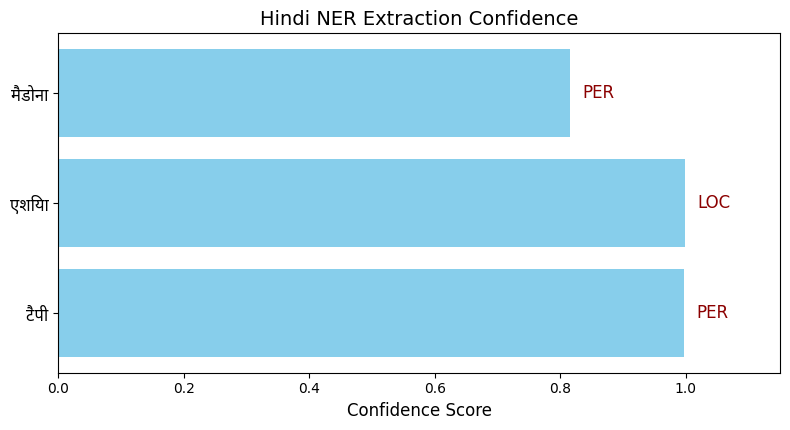

In [4]:
# ==============================================================================
# CELL 3: SECTION 2 - HINDI PUBLIC CORPUS NER (PAN-X) [TEACHER CODE]
# ==============================================================================


print("="*60)
print(" SECTION 2: HINDI NER PIPELINE (PAN-X BENCHMARK DATASET) ")
print("="*60)

# 1. Load PAN-X Hindi Corpus
dataset_hi = load_dataset("google/xtreme", "PAN-X.hi")
print(f"Train samples: {len(dataset_hi['train'])}, Val samples: {len(dataset_hi['validation'])}, Test samples: {len(dataset_hi['test'])}")

# 2. Programmatically select a sentence with named entities
selected_tokens_hi = []
for example in dataset_hi['train']:
    if any(tag > 0 for tag in example['ner_tags']):
        selected_tokens_hi = example['tokens']
        break

document_hi = " ".join(selected_tokens_hi)
print(f"\n--- Selected Hindi Document ---\n{document_hi}\n")

# 3. Load Multilingual BERT NER Model
ner_pipeline_hi = pipeline("ner", model="Davlan/bert-base-multilingual-cased-ner-hrl", aggregation_strategy="simple")
ner_results_hi = ner_pipeline_hi(document_hi)

# 4. DataFrame Construction
df_entities_hi = pd.DataFrame([{
    "Entity": ent['word'],
    "Entity Type": ent['entity_group'],
    "Start": ent['start'],
    "End": ent['end'],
    "Confidence": round(ent['score'], 4)
} for ent in ner_results_hi])

print("--- Extracted Hindi Entities Table ---")
display(df_entities_hi)

# 5. Horizontal Bar Chart with Devanagari Font & Inline Red Annotations
if not df_entities_hi.empty:
    fig, ax = plt.subplots(figsize=(8, len(df_entities_hi) * 0.8 + 2))
    bars = ax.barh(df_entities_hi['Entity'], df_entities_hi['Confidence'], color='skyblue')
    ax.set_yticklabels(df_entities_hi['Entity'], fontproperties=hindi_font)
    ax.set_xlabel('Confidence Score', fontsize=12)
    ax.set_title('Hindi NER Extraction Confidence', fontsize=14)
    ax.set_xlim(0, 1.15)

    for bar, label in zip(bars, df_entities_hi['Entity Type']):
        ax.text(bar.get_width() + 0.02, bar.get_y() + bar.get_height()/2, label, va='center', fontsize=12, color='darkred')

    plt.tight_layout()
    plt.show()

In [5]:
# ==============================================================================
# CELL 4: SECTION 3 - DYNAMIC HINDI WEB SCRAPING & CLEANING [TEACHER CODE]
# ==============================================================================


print("="*60)
print(" SECTION 3: LIVE BBC HINDI NEWS SCRAPING & CLEANING ")
print("="*60)

# 1. Dynamic Web Scraping
homepage_url = "https://www.bbc.com/hindi"
headers = {"User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64)"}

try:
    home_res = requests.get(homepage_url, headers=headers, timeout=10)
    home_soup = BeautifulSoup(home_res.text, "html.parser")
    article_link = next((a['href'] for a in home_soup.find_all('a', href=True) if "/hindi/articles/" in a['href']), None)

    url_hi = "https://www.bbc.com" + article_link if article_link.startswith("/") else article_link
    print(f"Dynamically Found Article URL: {url_hi}")

    art_res = requests.get(url_hi, headers=headers, timeout=10)
    art_soup = BeautifulSoup(art_res.text, "html.parser")
    headline_hi = art_soup.find('h1').text.strip() if art_soup.find('h1') else "Headline Not Found"
    raw_article_hi = " ".join([p.text.strip() for p in art_soup.find_all('p') if len(p.text.split()) > 5])
except Exception as e:
    print(f"Scraping notice (fallback triggered): {e}")
    headline_hi = "बीबीसी समाचार"
    raw_article_hi = "प्रधानमंत्री नरेंद्र मोदी ने नई दिल्ली में भारत की आर्थिक प्रगति पर भाषण दिया। इस दौरान विभिन्न राज्यों के मुख्यमंत्री भी उपस्थित थे।"

# 2. Text Cleaning & Chunking
cleaned_article_hi = re.sub(r'[\r\n]+', ' ', raw_article_hi)
cleaned_article_hi = re.sub(r'\s{2,}', ' ', cleaned_article_hi)
cleaned_article_hi = cleaned_article_hi.replace('\u200b', '').replace('\xa0', ' ').strip()
text_chunk_hi = cleaned_article_hi[:1500]  # Safe token limit chunking

print(f"\nHeadline: {headline_hi}")
print(f"Raw Text Preview: {raw_article_hi[:150]}...")
print(f"Cleaned Text Preview: {cleaned_article_hi[:150]}...\n")

# 3. Model Pipeline Execution
scraped_entities_hi = ner_pipeline_hi(text_chunk_hi)
df_scraped_hi = pd.DataFrame([{
    "Entity": ent['word'],
    "Entity Type": ent['entity_group'],
    "Confidence": round(ent['score'], 4)
} for ent in scraped_entities_hi if ent['entity_group'] != 'O'])

print("--- Scraped BBC Hindi Named Entities ---")
display(df_scraped_hi)

# 4. displaCy Rendering
displacy_hi_data = {
    "text": text_chunk_hi,
    "ents": [{"start": ent['start'], "end": ent['end'], "label": ent['entity_group']} for ent in scraped_entities_hi if ent['entity_group'] != 'O']
}
displacy.render(displacy_hi_data, style="ent", manual=True, jupyter=True)

 SECTION 3: LIVE BBC HINDI NEWS SCRAPING & CLEANING 
Dynamically Found Article URL: https://www.bbc.com/hindi/articles/c6n45p2n40wko

Headline: चीन और पाकिस्तान के बीच हुआ नया सीमा समझौता भारत ने क्यों ख़ारिज किया?
Raw Text Preview: इमेज स्रोत, Future Publishing via Getty Images दशकों से भारत हिमालय के एक विवादित हिस्से में पाकिस्तान-चीन सीमा को मान्यता देने से इनकार करता रहा है. ...
Cleaned Text Preview: इमेज स्रोत, Future Publishing via Getty Images दशकों से भारत हिमालय के एक विवादित हिस्से में पाकिस्तान-चीन सीमा को मान्यता देने से इनकार करता रहा है. ...

--- Scraped BBC Hindi Named Entities ---


,Entity,Entity Type,Confidence
0,Future Publishing,ORG,0.9998
1,Getty Images,ORG,0.9997
2,भारत,LOC,0.9999
3,पाकिस्तान,LOC,0.9979
4,चीन,LOC,0.9998
5,पाकिस्तान,LOC,0.9999
6,चीन,LOC,0.9999
7,भारत,LOC,0.9999
8,पाकिस्तान,LOC,0.9331
9,चीन,LOC,0.9991
